# MSBD 566 — Advanced Classification & Decision Analytics
## Hands-On Practice Notebook

Tonight's lecture covered a lot: thresholds, calibration, cost-sensitive learning, rare-event metrics, classifier comparison. This notebook is where all of that becomes your own code, on the same real dataset, so you can see it, break it, and rebuild it in your own time.

**What you'll rebuild tonight, for real:**

| Step | What you'll do |
|---|---|
| 0 | Set up and load the real diabetes readmission data |
| 1 | Build a classification-ready dataset (same 8 features, patient split) |
| 2 | Fit logistic regression, and read its odds ratios correctly |
| 3 | See the 0.5-threshold trap with your own eyes |
| 4 | Sweep every threshold — precision vs. recall |
| 5 | ROC curve and AUC |
| 6 | Precision-Recall curve — the honest view for rare events |
| 7 | Check calibration — does "70%" really mean 70%? |
| 8 | Cost-sensitive learning with `class_weight` |
| 9 | Quick comparison: Tree, Forest, SVM vs. logistic regression |
| 10 | Challenge questions — **no AI, these are yours to work through** |

Let's go.


---
## Step 0 — Setup

Same habit as every notebook this semester: fetch the data ourselves, and make sure scikit-learn is actually installed before we hit a wall three cells from now.


In [1]:
import os
import urllib.request
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 200)

DATA_URL = "https://archive.ics.uci.edu/static/public/296/diabetes+130-us+hospitals+for+years+1999-2008.zip"
if not os.path.exists("diabetic_data.csv"):
    urllib.request.urlretrieve(DATA_URL, "diabetes_data.zip")
    with zipfile.ZipFile("diabetes_data.zip") as z:
        z.extractall(".")

try:
    import sklearn
except ModuleNotFoundError:
    %pip install scikit-learn
    import sklearn

data = pd.read_csv("diabetic_data.csv")
data = data.replace('?', np.nan)
print("scikit-learn version:", sklearn.__version__)
print("Raw shape:", data.shape)

scikit-learn version: 1.6.1
Raw shape: (101766, 50)


---
## Step 1 — Build a Classification-Ready Dataset

Same target as our whole semester: `readmit_30`, 1 if a patient came back within 30 days, 0 otherwise. Same 8 numeric features from tonight's lecture, same patient-grouped split — no new patient can leak between train and test, exactly like Week 3.


In [2]:
# Clean, same decisions as our semester-long pipeline
data = data[~data['discharge_disposition_id'].isin([11, 13, 14, 19, 20, 21])]  # died/hospice -> undefined outcome
data = data[data['gender'] != 'Unknown/Invalid']
data['readmit_30'] = (data['readmitted'] == '<30').astype(int)

age_order = ['[0-10)','[10-20)','[20-30)','[30-40)','[40-50)','[50-60)','[60-70)','[70-80)','[80-90)','[90-100)']
age_map = {b: i for i, b in enumerate(age_order)}
data['age_ord'] = data['age'].map(age_map)

FEATURES = ['age_ord', 'time_in_hospital', 'num_lab_procedures', 'num_medications',
            'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']
TARGET = 'readmit_30'

clf_data = data[FEATURES + [TARGET, 'patient_nbr']].dropna().copy()
print("Classification-ready rows:", clf_data.shape[0])
print("Positive rate (readmit_30 == 1):", round(clf_data[TARGET].mean() * 100, 1), "%")

from sklearn.model_selection import GroupShuffleSplit

X = clf_data[FEATURES]
y = clf_data[TARGET]
groups = clf_data['patient_nbr']

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

overlap = set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])
print(f"Train: {X_train.shape} | Test: {X_test.shape} | Patient overlap: {len(overlap)}")
assert len(overlap) == 0

Classification-ready rows: 99340
Positive rate (readmit_30 == 1): 11.4 %
Train: (79567, 8) | Test: (19773, 8) | Patient overlap: 0


---
## Step 2 — Logistic Regression: Fit It, Then Read It Correctly

Fit the baseline model, then do the thing most people skip: **exponentiate the coefficients** before you say anything about them out loud. A raw coefficient is on the log-odds scale — meaningless on its own. `exp(coefficient)` is an odds ratio, and odds ratios multiply.


In [3]:
from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression(max_iter=1000).fit(X_train, y_train)

print(f"{'feature':20s} {'coef (log-odds)':>16s} {'odds ratio':>12s} {'% change in odds':>18s}")
for f, b in zip(FEATURES, logreg.coef_[0]):
    OR = np.exp(b)
    print(f"{f:20s} {b:>16.4f} {OR:>12.3f} {(OR-1)*100:>+17.1f}%")

print(f"\nintercept: {logreg.intercept_[0]:.4f}  (baseline log-odds when every feature is 0)")

feature               coef (log-odds)   odds ratio   % change in odds
age_ord                        0.0568        1.058              +5.8%
time_in_hospital               0.0232        1.023              +2.3%
num_lab_procedures             0.0007        1.001              +0.1%
num_medications                0.0047        1.005              +0.5%
number_outpatient             -0.0031        0.997              -0.3%
number_emergency               0.0331        1.034              +3.4%
number_inpatient               0.2724        1.313             +31.3%
number_diagnoses               0.0505        1.052              +5.2%

intercept: -3.2206  (baseline log-odds when every feature is 0)


**Read the biggest row out loud before moving on.** Whichever feature has the largest odds ratio — probably `number_inpatient` — translate it into a sentence: *"each additional [X] multiplies this patient's ODDS of readmission by [OR], a [(OR-1)*100]% change."* That sentence, not the raw coefficient, is what you'd actually say to a clinician.


---
## Step 3 — See the 0.5-Threshold Trap Yourself

Scikit-learn's `.predict()` uses a threshold of 0.5 by default. Let's see exactly what that does on a dataset where only about 11% of patients are positive.


In [4]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score

probs = logreg.predict_proba(X_test)[:, 1]   # probability of readmit_30 == 1
pred_default = (probs >= 0.5).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, pred_default).ravel()
print(f"At threshold 0.5:")
print(f"  True Positives (caught):   {tp}")
print(f"  False Negatives (missed):  {fn}")
print(f"  False Positives:           {fp}")
print(f"  True Negatives:            {tn}")
print(f"\n  Recall:    {recall_score(y_test, pred_default):.3f}")
print(f"  Precision: {precision_score(y_test, pred_default):.3f}")
print(f"  % of ALL patients flagged: {(tp+fp)/len(y_test)*100:.1f}%")

At threshold 0.5:
  True Positives (caught):   44
  False Negatives (missed):  2200
  False Positives:           20
  True Negatives:            17509

  Recall:    0.020
  Precision: 0.688
  % of ALL patients flagged: 0.3%


If your recall came out under 5%, you just reproduced the exact "88.8%-accuracy trap" from class with your own hands: the model is nearly silent at the default threshold. Time to move the line.


---
## Step 4 — Sweep Every Threshold: Precision vs. Recall

Instead of checking one threshold by hand, sweep across all of them and watch precision and recall trade off.


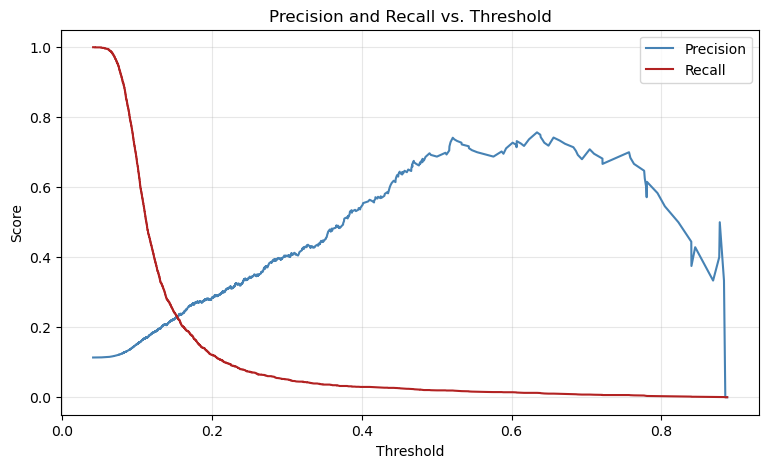

Balance point (precision ≈ recall) near threshold 0.15


In [5]:
from sklearn.metrics import precision_recall_curve

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, probs)

plt.figure(figsize=(9, 5))
plt.plot(pr_thresholds, precision_vals[:-1], label='Precision', color='steelblue')
plt.plot(pr_thresholds, recall_vals[:-1], label='Recall', color='firebrick')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision and Recall vs. Threshold')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Find the threshold where precision and recall are closest (the "balance point")
diffs = np.abs(precision_vals[:-1] - recall_vals[:-1])
balance_idx = np.argmin(diffs)
print(f"Balance point (precision ≈ recall) near threshold {pr_thresholds[balance_idx]:.2f}")

**Now pick YOUR OWN threshold, on purpose.** For our readmission problem, missing someone is worse than a false alarm — so we'd deliberately choose a threshold to the LEFT of the balance point, trading some precision for more recall. Try a few values below and see how the confusion matrix responds:


In [6]:
def evaluate_threshold(th):
    pred = (probs >= th).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    print(f"Threshold {th:.2f}:  Recall={recall_score(y_test, pred):.3f}  "
          f"Precision={precision_score(y_test, pred):.3f}  "
          f"Flagged={ (tp+fp)/len(y_test)*100:.1f}%  Missed(FN)={fn}")

for th in [0.5, 0.3, 0.2, 0.15, 0.1]:
    evaluate_threshold(th)

Threshold 0.50:  Recall=0.020  Precision=0.688  Flagged=0.3%  Missed(FN)=2200
Threshold 0.30:  Recall=0.051  Precision=0.403  Flagged=1.4%  Missed(FN)=2130
Threshold 0.20:  Recall=0.121  Precision=0.285  Flagged=4.8%  Missed(FN)=1972
Threshold 0.15:  Recall=0.242  Precision=0.224  Flagged=12.3%  Missed(FN)=1702
Threshold 0.10:  Recall=0.671  Precision=0.152  Flagged=50.2%  Missed(FN)=739


Threshold 0.30:  Recall=0.051  Precision=0.403  Flagged=1.4%  Missed(FN)=2130


Threshold 0.20:  Recall=0.121  Precision=0.285  Flagged=4.8%  Missed(FN)=1972
Threshold 0.15:  Recall=0.242  Precision=0.224  Flagged=12.3%  Missed(FN)=1702
Threshold 0.10:  Recall=0.671  Precision=0.152  Flagged=50.2%  Missed(FN)=739


---
## Step 5 — The ROC Curve and AUC

The ROC curve sweeps every threshold automatically and plots True Positive Rate against False Positive Rate. AUC compresses the whole curve into one number.


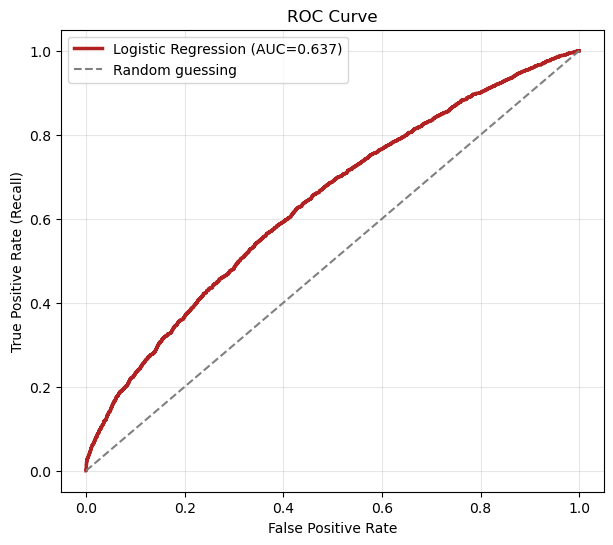

AUC: 0.637


In [7]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, roc_thresholds = roc_curve(y_test, probs)
auc = roc_auc_score(y_test, probs)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='firebrick', linewidth=2.5, label=f'Logistic Regression (AUC={auc:.3f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random guessing')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curve')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"AUC: {auc:.3f}")

---
## Step 6 — Precision-Recall Curve: The Honest View

Remember from class: ROC can look generous on a rare-event problem, because most patients are negative and true negatives don't count against it. Precision-Recall is more honest here. Same model, same test set — compare the two summary numbers.


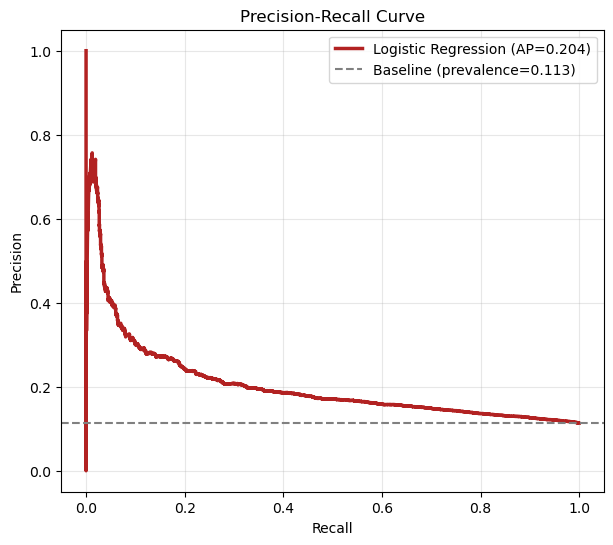

AUC:              0.637
Average Precision: 0.204
Same model, same patients. Notice how different these two numbers FEEL.


In [8]:
from sklearn.metrics import average_precision_score

ap = average_precision_score(y_test, probs)
baseline = y_test.mean()

plt.figure(figsize=(7, 6))
plt.plot(recall_vals, precision_vals, color='firebrick', linewidth=2.5, label=f'Logistic Regression (AP={ap:.3f})')
plt.axhline(baseline, color='gray', linestyle='--', label=f'Baseline (prevalence={baseline:.3f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"AUC:              {auc:.3f}")
print(f"Average Precision: {ap:.3f}")
print("Same model, same patients. Notice how different these two numbers FEEL.")

---
## Step 7 — Is Our Model Calibrated?

AUC and Average Precision both measure RANKING. Calibration measures something different: when the model says "70% risk," are roughly 70 out of 100 such patients actually readmitted?


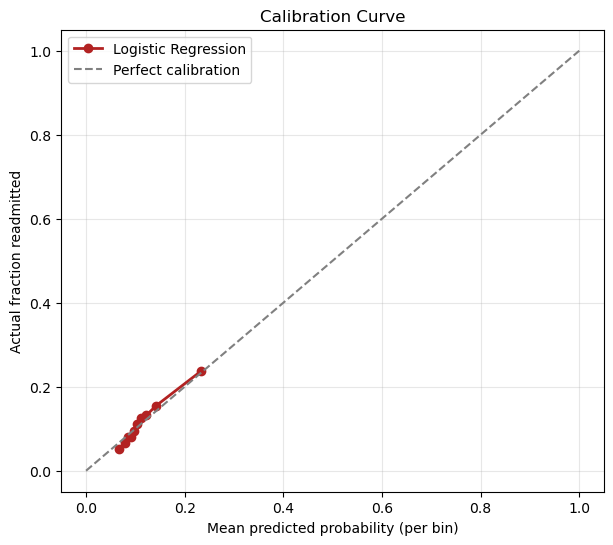

In [9]:
from sklearn.calibration import calibration_curve

frac_positive, mean_predicted = calibration_curve(y_test, probs, n_bins=10, strategy='quantile')

plt.figure(figsize=(7, 6))
plt.plot(mean_predicted, frac_positive, marker='o', color='firebrick', linewidth=2, label='Logistic Regression')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Perfect calibration')
plt.xlabel('Mean predicted probability (per bin)')
plt.ylabel('Actual fraction readmitted')
plt.title('Calibration Curve')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Logistic regression tends to land close to this diagonal, because it directly optimizes log-loss during training — good calibration is almost a free side effect. Keep this plot in mind for Challenge Question 3, where you'll check whether a DIFFERENT model family is as well-behaved.


---
## Step 8 — Cost-Sensitive Learning: `class_weight`

Threshold-moving happens AFTER training. `class_weight` changes what the model optimizes for DURING training — telling it directly that missing a positive case should hurt more.


In [10]:
logreg_weighted = LogisticRegression(max_iter=1000, class_weight={0: 1, 1: 8}).fit(X_train, y_train)
probs_weighted = logreg_weighted.predict_proba(X_test)[:, 1]
pred_weighted = (probs_weighted >= 0.5).astype(int)

print("Plain logistic regression, threshold 0.5:")
evaluate_threshold(0.5)

print("\nCost-sensitive logistic regression (class_weight={0:1, 1:8}), threshold 0.5:")
tn, fp, fn, tp = confusion_matrix(y_test, pred_weighted).ravel()
print(f"  Recall={recall_score(y_test, pred_weighted):.3f}  Precision={precision_score(y_test, pred_weighted):.3f}  "
      f"Flagged={(tp+fp)/len(y_test)*100:.1f}%  Missed(FN)={fn}")

Plain logistic regression, threshold 0.5:
Threshold 0.50:  Recall=0.020  Precision=0.688  Flagged=0.3%  Missed(FN)=2200

Cost-sensitive logistic regression (class_weight={0:1, 1:8}), threshold 0.5:
  Recall=0.512  Precision=0.169  Flagged=34.3%  Missed(FN)=1094


Notice: with `class_weight` doing the work, we didn't even need to touch the threshold to see recall jump. The model itself now treats a false negative as 8 times more costly than a false positive — it moved its own decision boundary to reflect that.


---
## Step 9 — Quick Comparison: Four Classifiers, Same Question

One last practice rep: fit Decision Tree, Random Forest, and a linear SVM on the same data, and compare all four the way we did in class.


In [11]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

tree = DecisionTreeClassifier(max_depth=4, min_samples_leaf=200, class_weight='balanced', random_state=42).fit(X_train, y_train)
forest = RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=50, class_weight='balanced', random_state=42, n_jobs=-1).fit(X_train, y_train)
svm = LinearSVC(class_weight='balanced', max_iter=5000, random_state=42).fit(X_train_s, y_train)

results = {
    'Logistic Regression': roc_auc_score(y_test, probs),
    'Decision Tree': roc_auc_score(y_test, tree.predict_proba(X_test)[:, 1]),
    'Random Forest': roc_auc_score(y_test, forest.predict_proba(X_test)[:, 1]),
    'SVM (linear)': roc_auc_score(y_test, svm.decision_function(X_test_s)),
}
print(f"{'Model':22s} {'Test AUC':>10s}")
for name, score in sorted(results.items(), key=lambda kv: -kv[1]):
    print(f"{name:22s} {score:>10.3f}")

Model                    Test AUC
Random Forest               0.643
Logistic Regression         0.637
SVM (linear)                0.635
Decision Tree               0.632


How close are these numbers to each other? If they're all within a point or two of AUC, that's the same honest lesson from class: on this basic feature set, algorithm choice barely moves the needle. Better features would likely help more than a fancier model.


---
## 🏆 Challenge Questions

> ⚠️ **No AI for these.** Work through them yourself first — the goal is that YOU can explain every line, not that the notebook looks finished. If you're stuck after a real attempt, bring your attempt to office hours.

**C1 — Pick a threshold and defend it.** Using the precision/recall-vs-threshold plot from Step 4, choose a specific threshold for the readmission problem, different from any value already tried above. In a markdown cell, write 2–3 sentences defending your choice: what recall and precision does it give you, and why is that an acceptable trade-off for a hospital readmission alert?

**C2 — Find the odds ratio for a different feature.** Refit logistic regression using at least two NEW features from `data` that we haven't used yet (e.g., `num_procedures`, `number_diagnoses` if not already included, or an encoded categorical column). Report the odds ratio for each and write the plain-English sentence, the way Step 2 modeled for you.

**C3 — Check a DIFFERENT model's calibration.** Using the Random Forest from Step 9, plot its calibration curve the same way Step 7 did for logistic regression (`forest.predict_proba(X_test)[:, 1]` instead of `probs`). Is it closer to or further from the diagonal? Write one sentence on whether this matches what class predicted about tree-based models.

**C4 — Cost-sensitive vs. threshold-moving: which gets you further?** Using the cost-sensitive model from Step 8, sweep ITS thresholds the same way Step 4 did for the plain model. Does combining `class_weight` AND threshold-tuning get you a better recall/precision trade-off than either alone?

**C5 (stretch) — Multiclass, for real.** The raw `readmitted` column (before we collapsed it in Week 2) has three classes: `NO`, `>30`, `<30`. Refit a `LogisticRegression(multi_class='multinomial')` predicting all three classes directly from the same 8 features, and report the per-class precision and recall using `classification_report` from `sklearn.metrics`. Is predicting all three classes at once harder than our binary version? Why might that be?


In [17]:
# C1 — your threshold choice and justification here

threshold = 0.18
pred = (probs >= threshold).astype(int)

print("Threshold:", threshold)
print("Recall:", round(recall_score(y_test, pred), 3))
print("Precision:", round(precision_score(y_test, pred, zero_division=0), 3))


Threshold: 0.18
Recall: 0.158
Precision: 0.272


I chose a threshold of 0.18 because I wanted to catch more patients who may be readmitted within 30 days. At this threshold, my model had a recall of 0.158 and precision of 0.272. I think this is a reasonable trade-off because missing a patient who may need additional care could be more concerning than sending some extra alerts.

In [18]:
# C2 — your code here
new_features = ['num_procedures', 'admission_type_id']

X_new = data.loc[clf_data.index, new_features].copy()

X_train_new = X_new.iloc[train_idx]
X_test_new = X_new.iloc[test_idx]

logreg_new = LogisticRegression(max_iter=1000)
logreg_new.fit(X_train_new, y_train)

for f, b in zip(new_features, logreg_new.coef_[0]):
    OR = np.exp(b)
    print(f, "Odds Ratio:", round(OR, 3))

num_procedures Odds Ratio: 0.985
admission_type_id Odds Ratio: 0.972


I refitted logistic regression using num_procedures and admission_type_id to see how these features were associated with 30-day readmission. The odds ratio for num_procedures was 0.985, while the odds ratio for admission_type_id was 0.972. These results show how the model's estimated odds of readmission change with each feature, although admission_type_id is a coded category and should be interpreted carefully.

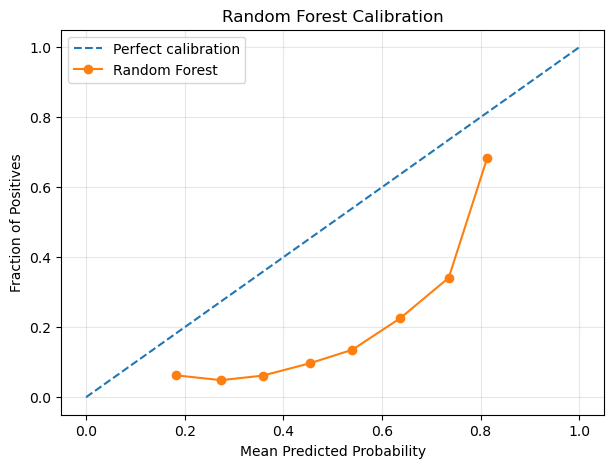

In [19]:
# C3 — your code here
from sklearn.calibration import calibration_curve

forest_probs = forest.predict_proba(X_test)[:, 1]

fraction_pos, mean_pred = calibration_curve(
    y_test, forest_probs, n_bins=10
)

plt.figure(figsize=(7, 5))
plt.plot([0, 1], [0, 1], '--', label='Perfect calibration')
plt.plot(mean_pred, fraction_pos, marker='o', label='Random Forest')

plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')
plt.title('Random Forest Calibration')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [20]:
# C4 — your code here
for threshold in [0.2, 0.3, 0.4, 0.5]:
    pred_plain = (probs >= threshold).astype(int)
    pred_weighted = (probs_weighted >= threshold).astype(int)

    print("Threshold:", threshold)

    print("Plain Recall:", round(recall_score(y_test, pred_plain), 3))
    print("Plain Precision:", round(precision_score(y_test, pred_plain, zero_division=0), 3))

    print("Weighted Recall:", round(recall_score(y_test, pred_weighted), 3))
    print("Weighted Precision:", round(precision_score(y_test, pred_weighted, zero_division=0), 3))
    print()

Threshold: 0.2
Plain Recall: 0.121
Plain Precision: 0.285
Weighted Recall: 1.0
Weighted Precision: 0.113

Threshold: 0.3
Plain Recall: 0.051
Plain Precision: 0.403
Weighted Recall: 0.998
Weighted Precision: 0.114

Threshold: 0.4
Plain Recall: 0.029
Plain Precision: 0.55
Weighted Recall: 0.91
Weighted Precision: 0.125

Threshold: 0.5
Plain Recall: 0.02
Plain Precision: 0.688
Weighted Recall: 0.512
Weighted Precision: 0.169



In [21]:
# C5 (stretch) — your code here
from sklearn.metrics import classification_report

y_multi = data.loc[clf_data.index, 'readmitted']

y_train_multi = y_multi.iloc[train_idx]
y_test_multi = y_multi.iloc[test_idx]

multi_model = LogisticRegression(
    multi_class='multinomial',
    max_iter=1000
)

multi_model.fit(X_train, y_train_multi)

pred_multi = multi_model.predict(X_test)

print(classification_report(y_test_multi, pred_multi, zero_division=0))

/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


              precision    recall  f1-score   support

         <30       0.78      0.01      0.03      2244
         >30       0.49      0.24      0.32      6953
          NO       0.58      0.90      0.71     10576

    accuracy                           0.57     19773
   macro avg       0.62      0.38      0.35     19773
weighted avg       0.57      0.57      0.50     19773



---
### You made it through the whole toolkit

Logistic regression, read correctly instead of the common wrong way. The 0.5-threshold trap, reproduced with your own hands. A full threshold sweep. ROC and Precision-Recall, and why they can disagree. Calibration, checked rather than assumed. Cost-sensitive learning. And a real four-way classifier comparison.

Every number in this notebook came from the same dataset you've been building all semester. Next time you build ANY classifier — in this course or after it — you now have a mental checklist: don't trust the default threshold, check calibration before you show a probability to a human, and always ask whether the positive class is rare before you pick your evaluation metric.
